In [1]:
import sys
import utils as utils
from importlib import reload
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
reload(utils)
from tqdm import tqdm
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import plotting as plt_AMM

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (8, 5),
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
pylab.rcParams.update(params)
%config InlineBackend.figure_format = "retina"

import matplotlib
plt.rc('text', usetex=True)
plt.rc('text.latex', preamble=r'\usepackage{amsmath,amsfonts}')
dpi = 300

## Load parameters

In [5]:
import pickle

with open('data/params_env.pkl', 'rb') as f:
    params_env = pickle.load(f)

## Define environment

In [6]:
env = utils.environment_exp(**params_env)
risk_type = 'averse'

In [7]:
mins_per_step = 24*60/10_000

In [8]:
np.random.seed(100)

nsims = 1_000
strag_LP = '1'
strag_vn = 'exp'

S, Y, Z, X, nu, wealth, perf, rew, venue_wealth, A_a_hist, A_b_hist, A_W_hist, A_B_hist, rew_drift_hist = env.simulate_venue(nsims=nsims, strag_LP=strag_LP, strag_vn=strag_vn, verbose = True)

In [9]:
mins_per_step = 24*60/10_000
Nwindow = int(10/mins_per_step)

df = pd.DataFrame(data=np.concatenate((S.ravel().reshape(-1,1),Z.ravel().reshape(-1,1)),axis=1), columns=('S','Z'))
df['difference'] = df['S'] - df['Z']
diffs = df['difference'].rolling(Nwindow).mean()
diffs.dropna(inplace=True)

In [10]:
fs = 14
fsL = 19
plt.rcParams["font.size"] = fs

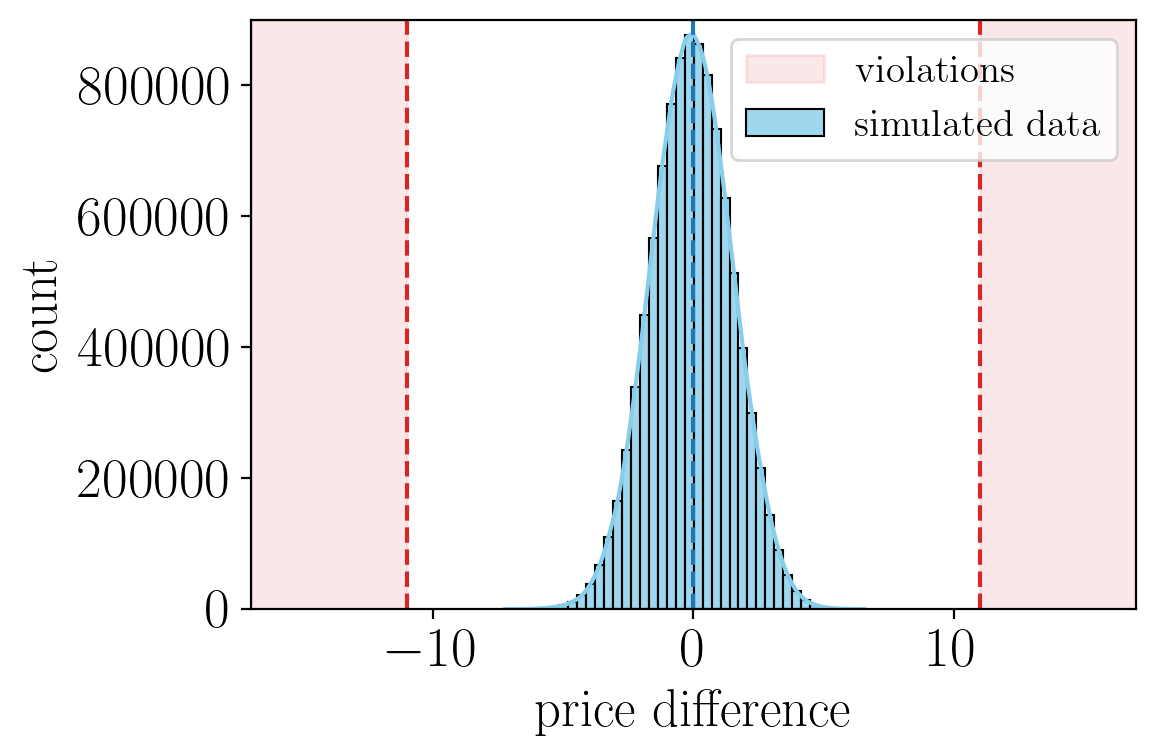

In [11]:
import seaborn as sns
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

x = -10.994492750981774

sns.histplot(data=diffs, bins=40, kde=True, color="skyblue", label = r'$\mathrm{simulated}$ $\mathrm{data}$', ax=axs, alpha =0.8)
axs.set_xlabel(r'$\mathrm{price\,\,difference}$', fontsize = fsL)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = fsL)

axs.axvline(0,linestyle = '--', color='tab:blue')
axs.axvline(x,linestyle = '--', color='tab:red')
axs.axvline(-x,linestyle = '--', color='tab:red')

xmin = -17
xmax = 17
ymax = 900_000

xaux_left = np.linspace(xmin, x, 100)
xaux_right = np.linspace(-x, xmax, 100)

axs.fill_between(xaux_left, ymax*np.ones_like(xaux_left), color = 'tab:red' , alpha=0.1, label= r'$\mathrm{violations}$')
axs.fill_between(xaux_right, ymax*np.ones_like(xaux_right), color = 'tab:red' , alpha=0.1)

plt.ylim([0,ymax])
plt.tight_layout()
plt.xlim([xmin,xmax])
plt.legend(fontsize=fs)

plt.tight_layout()
plt.savefig(f'figures/negative-intensity-regions-symm-simulations-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

In [12]:
qtl_Y = np.zeros((len(env.timesteps),3))
qtl_nu = np.zeros((len(env.timesteps),3))
qtl_rew = np.zeros((len(env.timesteps),3))
qtl_Z = np.zeros((len(env.timesteps),3))
qtl_S = np.zeros((len(env.timesteps),3))

for it, t in enumerate(env.timesteps):
    qtl_Y[it, :] = np.quantile(Y[it,:],[0.05,0.5,0.95],axis=0)
    qtl_nu[it, :] = np.quantile(nu[it,:],[0.05,0.5,0.95],axis=0)
    qtl_rew[it, :] = np.quantile(rew[it,:],[0.05,0.5,0.95],axis=0)
    qtl_Z[it, :] = np.quantile(Z[it,:],[0.05,0.5,0.95],axis=0)
    qtl_S[it, :] = np.quantile(S[it,:],[0.05,0.5,0.95],axis=0)

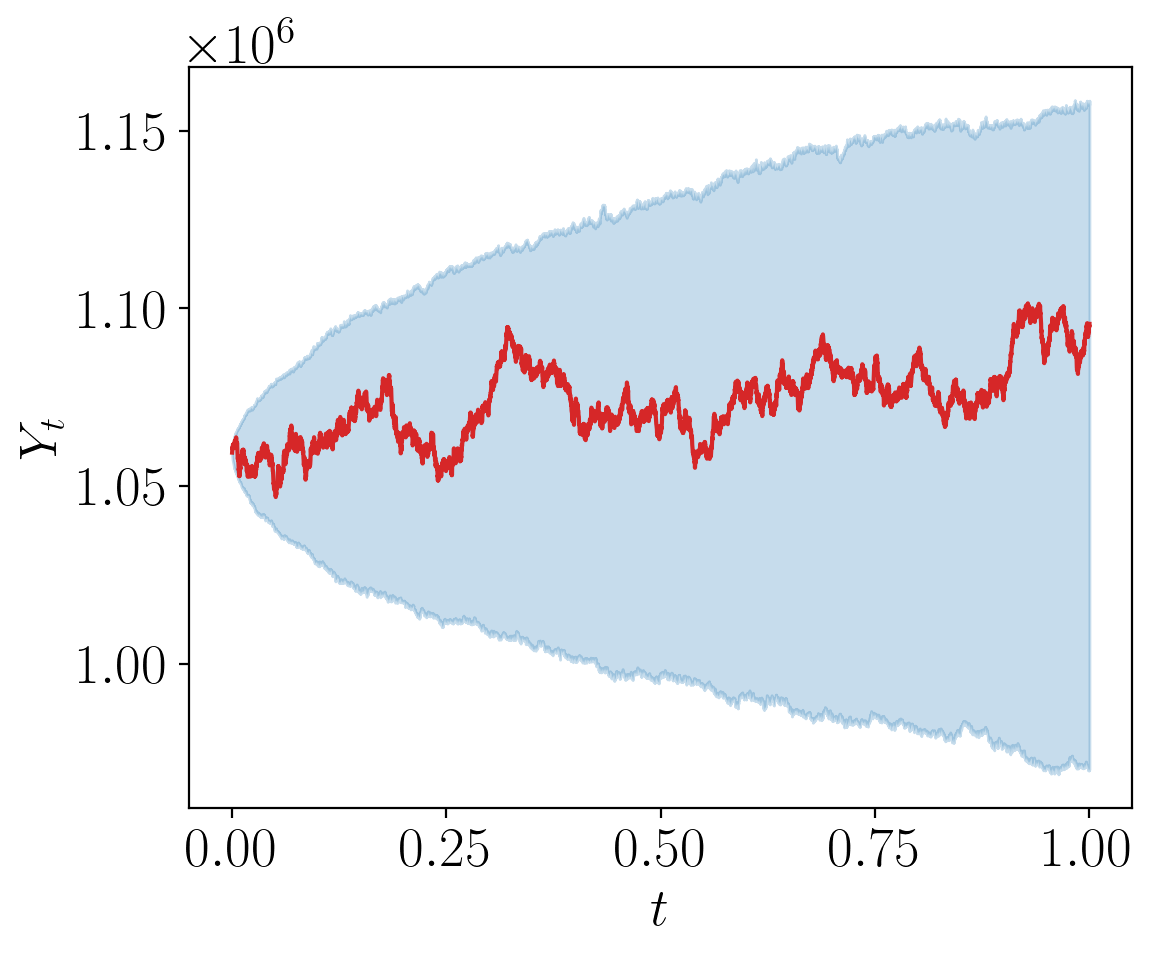

In [13]:
nsim = 53

fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, Y[:,nsim], label=r'$Y$', color ='tab:red')
plt.fill_between(env.timesteps,qtl_Y[:,0],qtl_Y[:,-1], color='tab:blue', alpha=0.25)
plt.xlabel(r'$t$', fontsize = fsL)
plt.ylabel(r'$Y_t$', fontsize = fsL)
plt.tight_layout()
plt.savefig(f'figures/baseline-sim-Y-paths-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

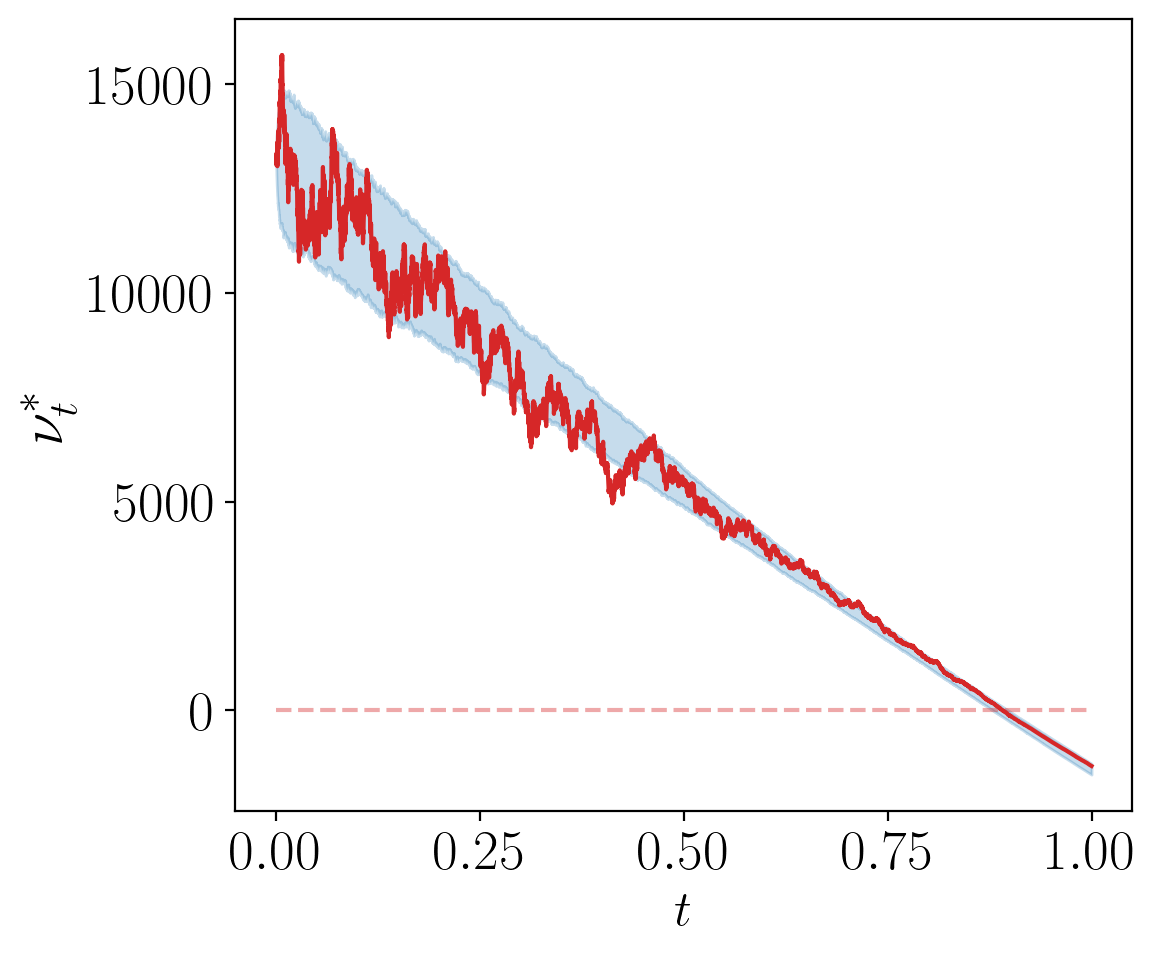

In [14]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, nu[:,nsim], label=r'$\nu$', color ='tab:red')
plt.fill_between(env.timesteps,qtl_nu[:,0],qtl_nu[:,-1], color='tab:blue', alpha=0.25)
plt.xlabel(r'$t$', fontsize = 18)
plt.ylabel(r'$\nu^*_t$', fontsize = 22)
plt.hlines(y = 0, xmin = 0, xmax = 1, linestyle = '--', alpha = 0.4, color='tab:red')
plt.tight_layout()
plt.savefig(f'figures/baseline-sim-nu-paths-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

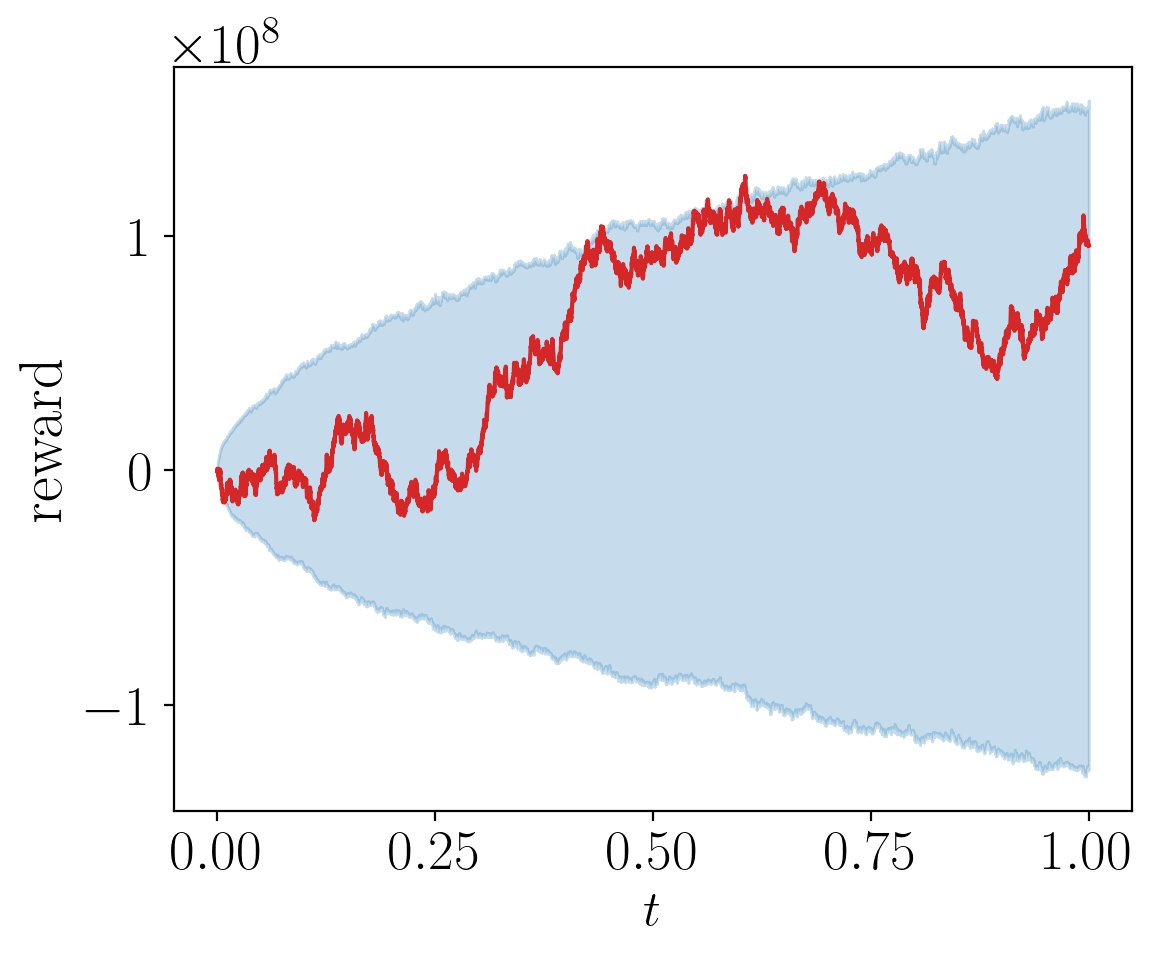

In [15]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, rew[:,nsim], label='reward', color ='tab:red')
plt.fill_between(env.timesteps,qtl_rew[:,0],qtl_rew[:,-1], color='tab:blue', alpha=0.25)
plt.xlabel(r'$t$', fontsize = 18)
plt.ylabel(r'$\mathrm{reward}$', fontsize = 22)
plt.tight_layout()
plt.savefig(f'figures/baseline-sim-rew-paths-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

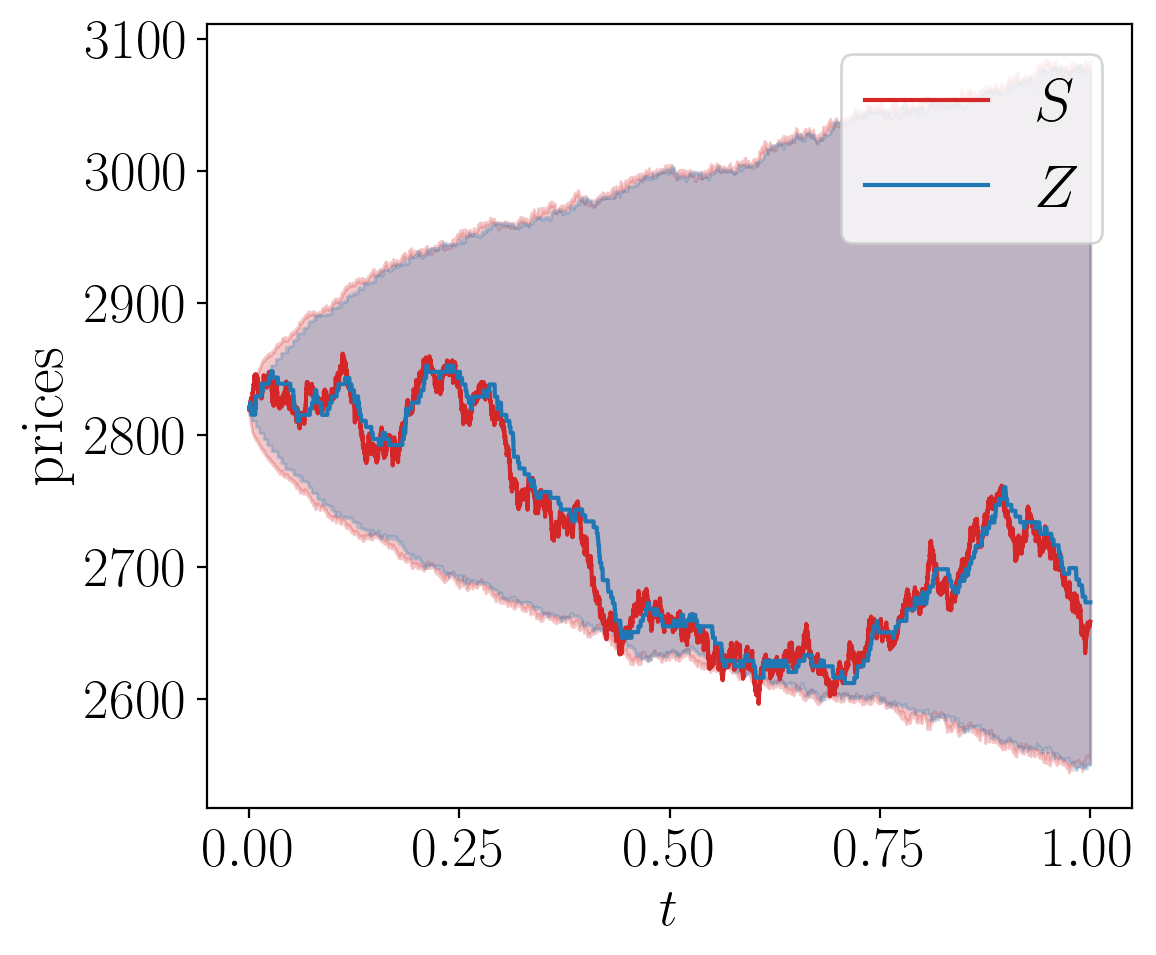

In [16]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, S[:,nsim], label=r'$S$', color ='tab:red')
plt.plot(env.timesteps, Z[:,nsim], label=r'$Z$', color ='tab:blue')

plt.fill_between(env.timesteps,qtl_S[:,0],qtl_S[:,-1], color='tab:red', alpha=0.25)
plt.fill_between(env.timesteps,qtl_Z[:,0],qtl_Z[:,-1], color='tab:blue', alpha=0.25)

plt.xlabel(r'$t$', fontsize = fsL)
plt.ylabel(r'$\mathrm{prices}$', fontsize = fsL+3)
plt.legend(fontsize = fsL+3)
plt.tight_layout()
plt.savefig(f'figures/baseline-sim-S-Z-paths-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

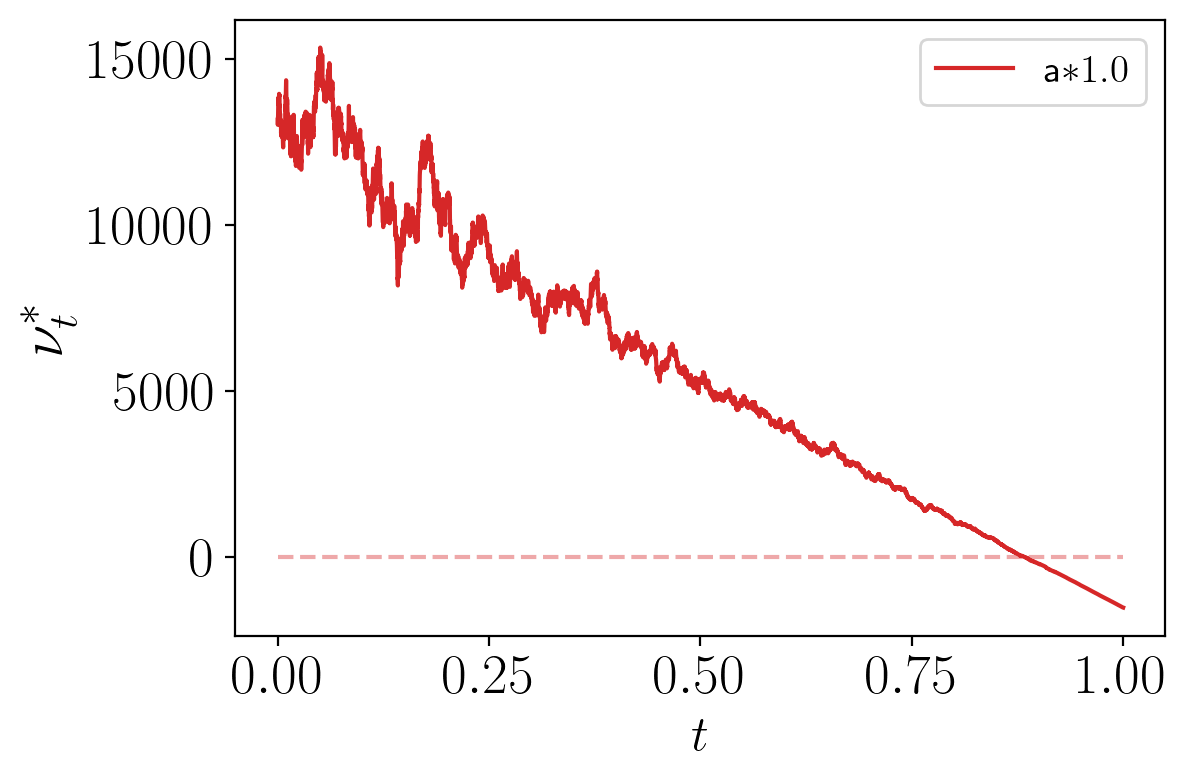

In [28]:
plt_AMM.stress_parameter_and_show_nu(environment= utils.environment_exp, parameter = 'tempLP', values=[1.],  params=params_env, 
                                     savefig = False, to_print='a', strag_vn = strag_vn, strag_LP = strag_LP)

In [19]:
values = [1,2,4,8,16]
colors = ['tab:red', 'tab:orange', 'skyblue', 'tab:green', 'tab:blue']

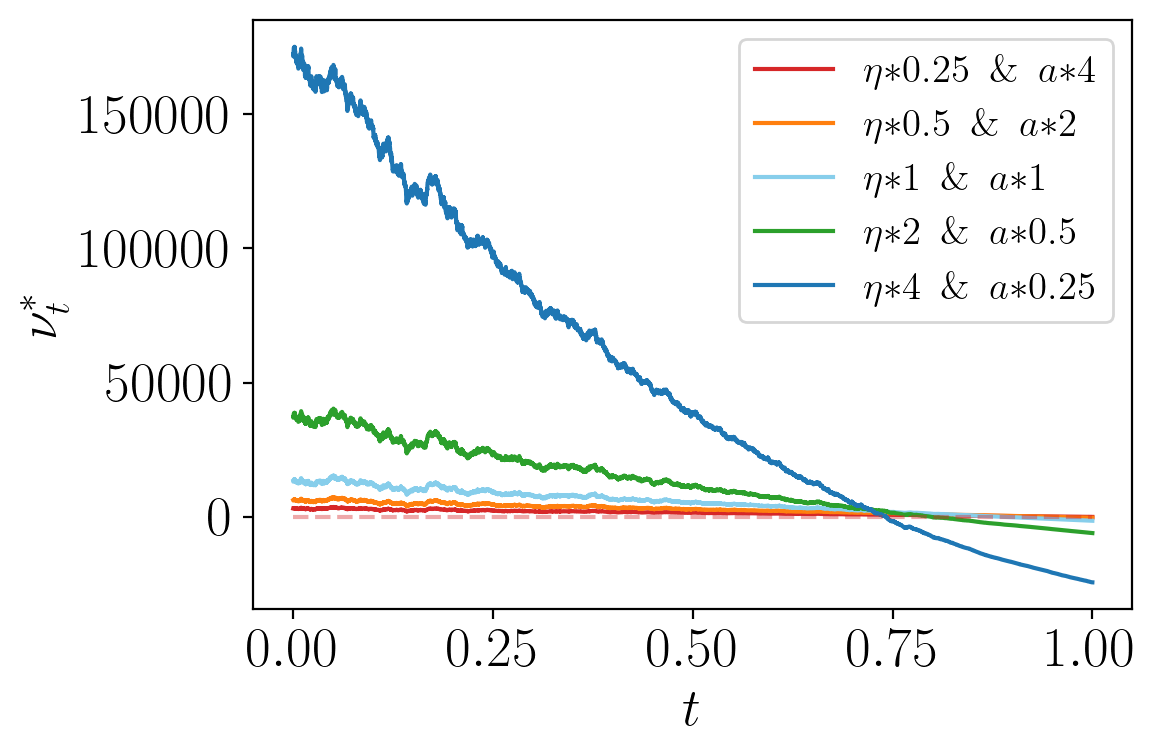

In [20]:
values1 = [1/4, 1/2, 1,2,4]
values2 = [4,2, 1,1/2,1/4]
plt_AMM.stress_two_parameters_two_sets_and_show_nu(environment= utils.environment_exp ,parameter1 = 'eta', parameter2 ='tempLP', values1 = values1, values2 = values2, params = params_env,
                                                   to_print1 =r'$\eta$', to_print2 = r'$a$', logScale = False, colors = colors,
                                                  savefig = True, filename = f'stress-eta-tempLP-{risk_type}', strag_vn = strag_vn, strag_LP = strag_LP)

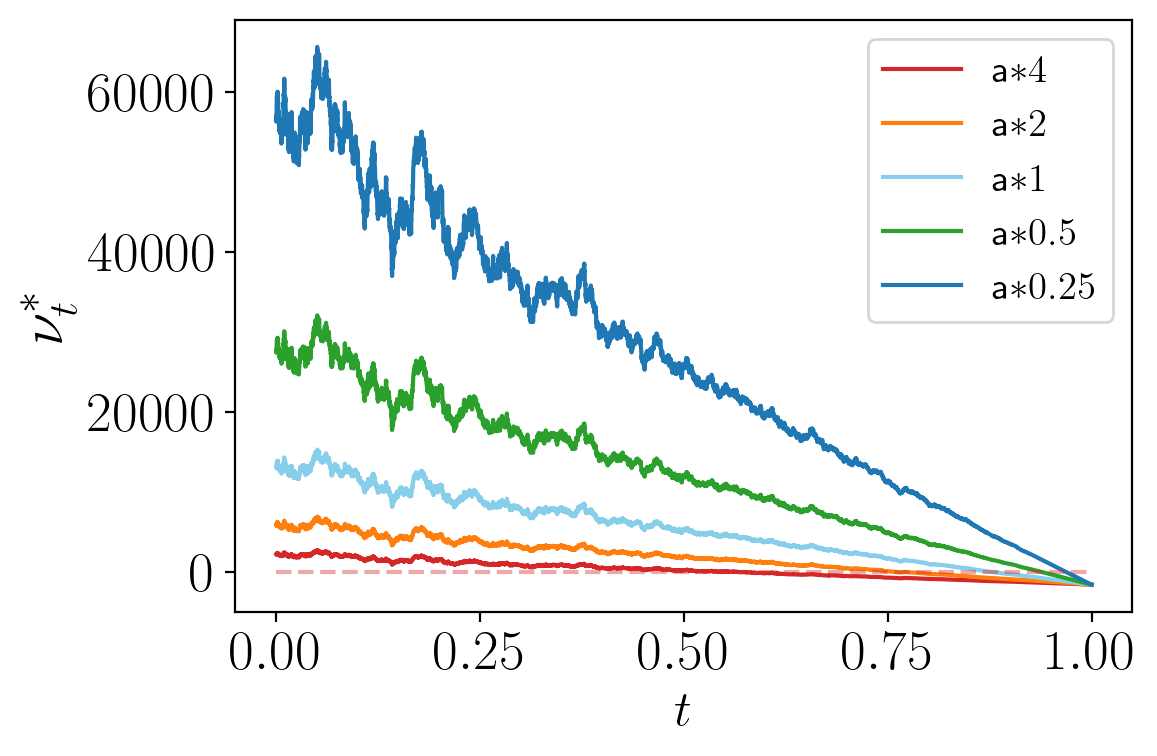

In [21]:
plt_AMM.stress_parameter_and_show_nu(environment= utils.environment_exp, parameter = 'tempLP', values=values2,  params=params_env, 
                                     savefig = True, filename = f'stress-tempLP-{risk_type}', to_print='a', strag_vn = strag_vn, strag_LP = strag_LP)

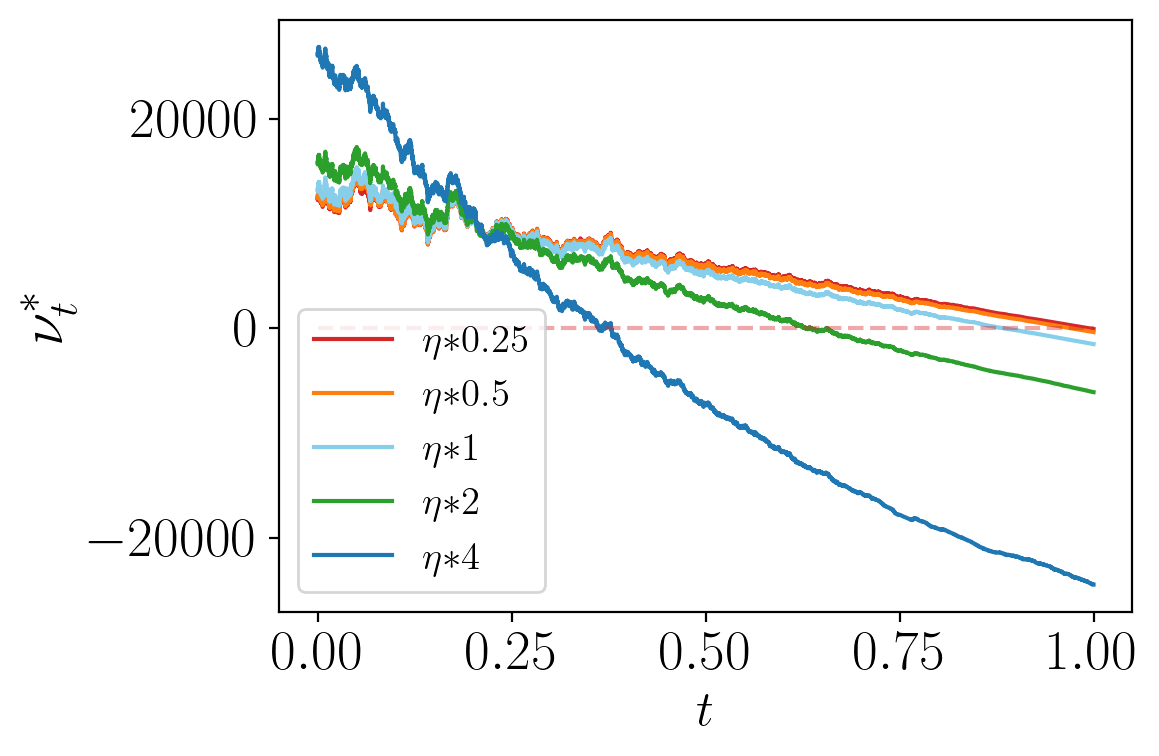

In [22]:
plt_AMM.stress_parameter_and_show_nu(environment= utils.environment_exp, parameter = 'eta', values = values1, params=params_env, to_print=r'$\eta$',
                                     savefig = True, filename = f'stress-eta-{risk_type}', strag_vn = strag_vn, strag_LP = strag_LP)

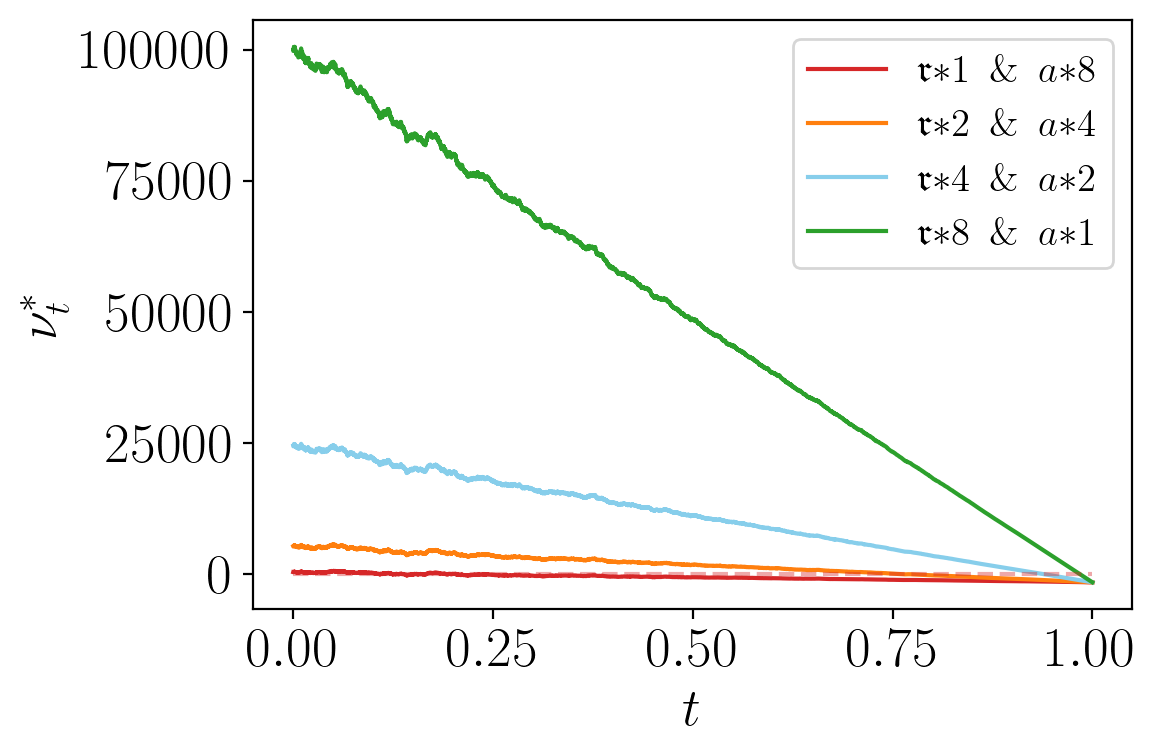

In [23]:
values1 = [1,2,4,8]
values2 = [8,4,2,1]
plt_AMM.stress_two_parameters_two_sets_and_show_nu(environment= utils.environment_exp, parameter1 = 'feeV', parameter2='tempLP', values1 = values1, values2 = values2, params=params_env,
                                                   to_print1 ='$\mathfrak{r}$', to_print2 = r'$a$', logScale = False, 
                                                  savefig = True, filename = f'stress-feeV-tempLP-{risk_type}', strag_vn = strag_vn, strag_LP = strag_LP)

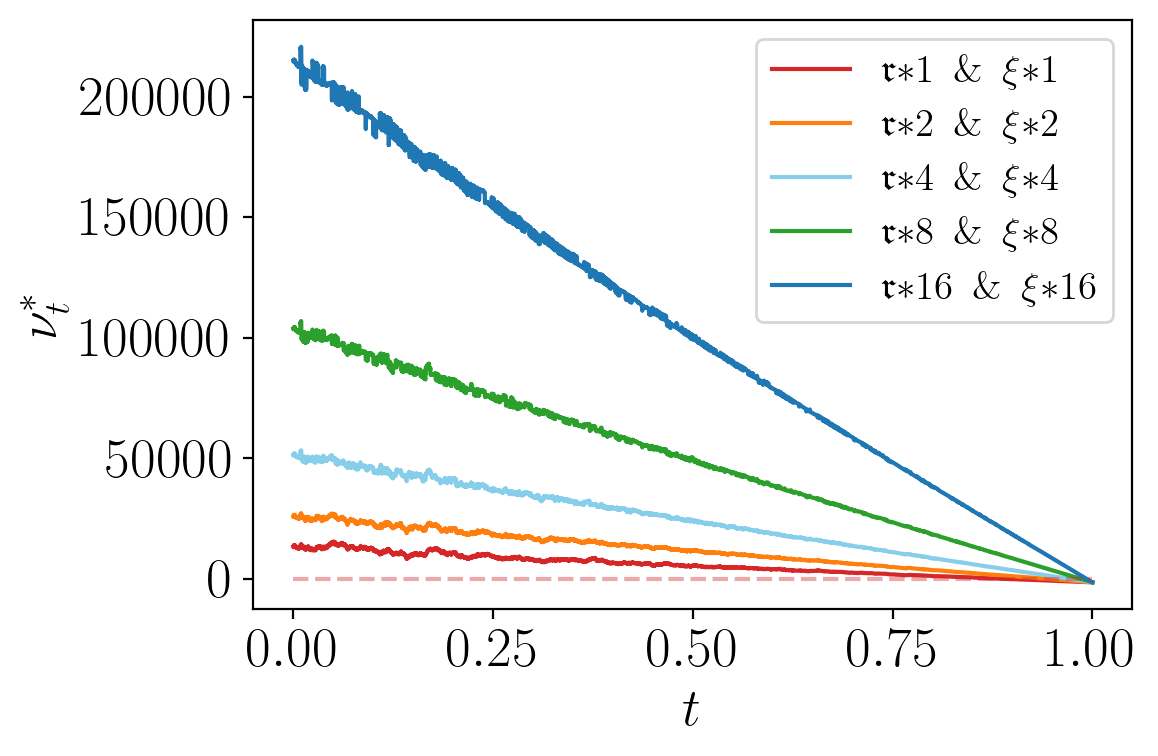

In [24]:
plt_AMM.stress_two_parameters_two_sets_and_show_nu(environment= utils.environment_exp, parameter1 = 'feeV', parameter2='xi', values1 = values, values2 = values, params=params_env,
                                                   to_print1 ='$\mathfrak{r}$', to_print2 = r'$\xi$',
                                                  savefig = True, filename = f'stress-feeV-xi-{risk_type}', strag_vn = strag_vn, strag_LP = strag_LP)

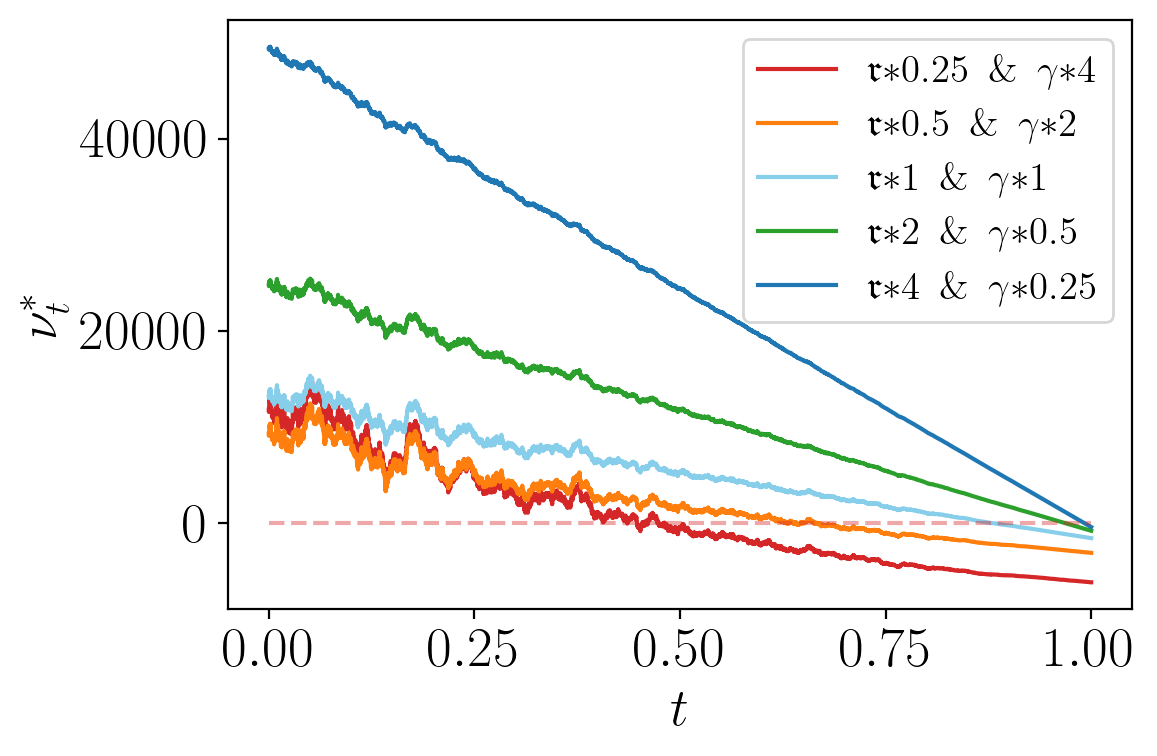

In [25]:
values1 = [1/4, 1/2, 1,2,4]
values2 = [4,2, 1,1/2,1/4]
plt_AMM.stress_two_parameters_two_sets_and_show_nu(environment= utils.environment_exp, parameter1 = 'feeV', parameter2='gamma', values1 = values1, values2 = values2, params=params_env,
                                                   to_print1 =r'$\mathfrak{r}$', to_print2 = r'$\gamma$',
                                                  savefig = True, filename = f'stress-feeV-gamma-{risk_type}', strag_vn = strag_vn, strag_LP = strag_LP)

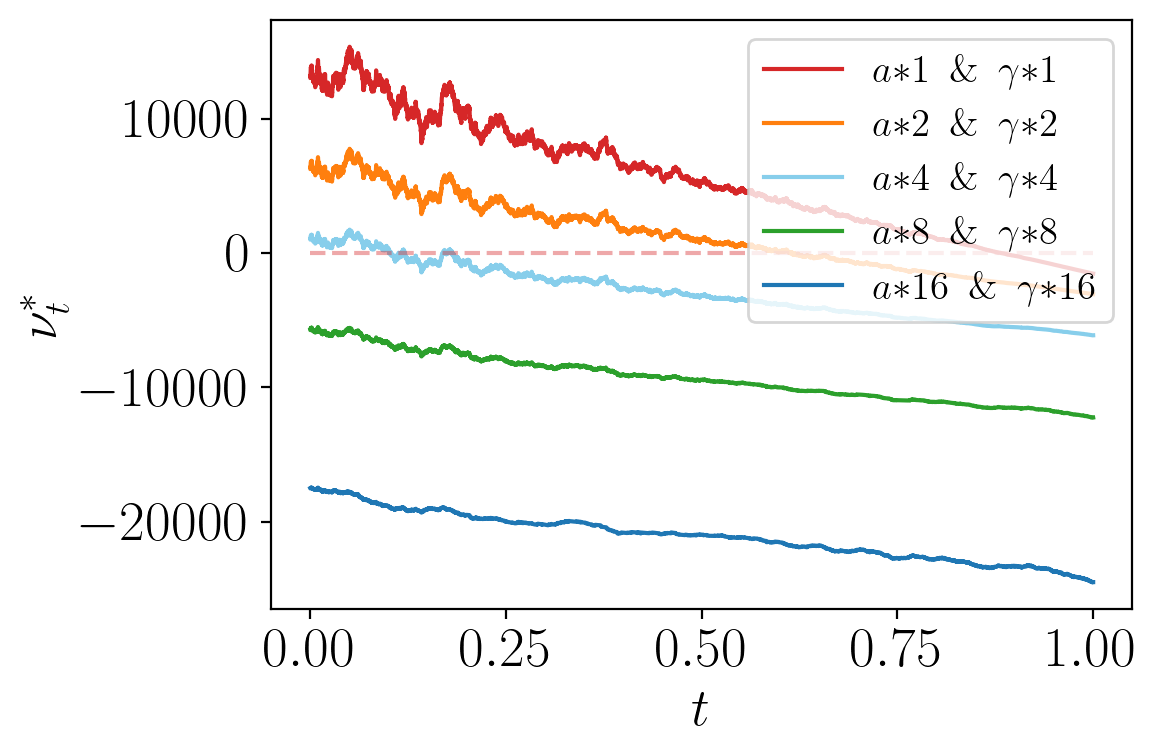

In [26]:
plt_AMM.stress_two_parameters_two_sets_and_show_nu(environment= utils.environment_exp, parameter1 = 'tempLP', parameter2 = 'gamma', values1 = values, values2 = values, params=params_env,
                                                   to_print1 =r'$a$', to_print2 = r'$\gamma$',
                                                  savefig = True, filename = f'stress-tempLP-gamma-{risk_type}', strag_vn = strag_vn, strag_LP = strag_LP)

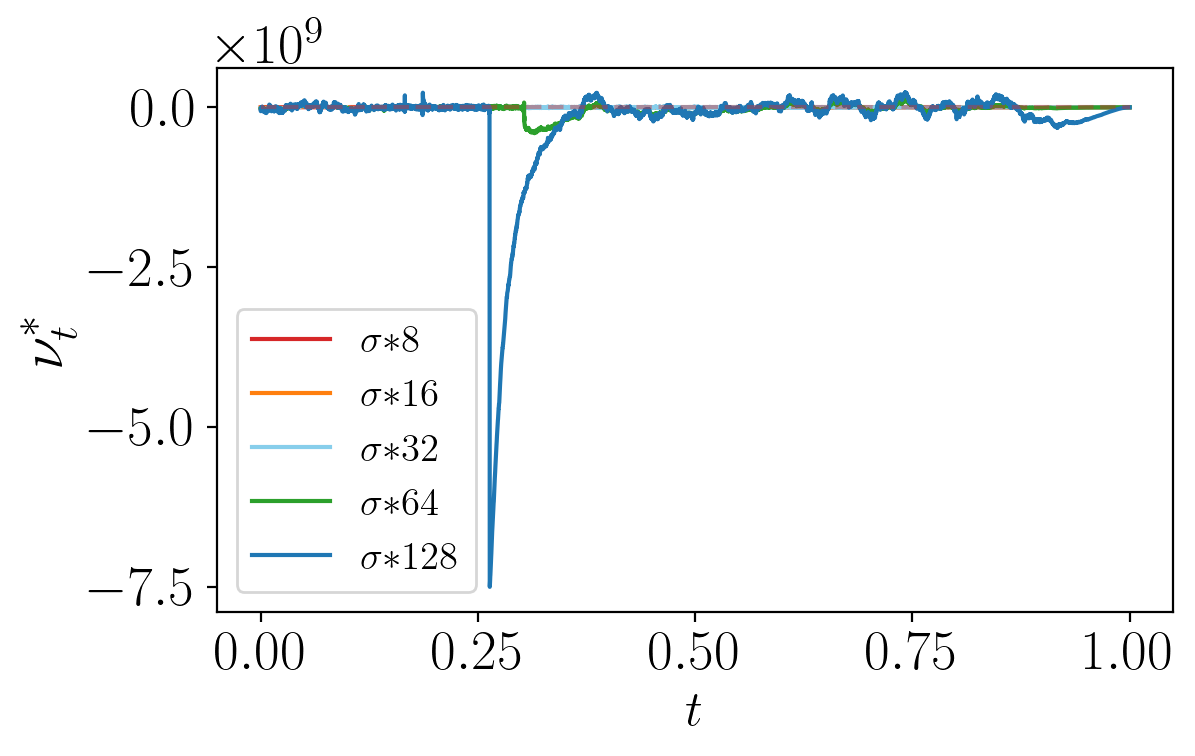

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [27]:
plt_AMM.stress_parameter_and_show_nu(environment= utils.environment_exp, parameter = 'sigma', values = [8,16,32,64,128], to_print=r'$\sigma$', params=params_env,
                                    savefig = True, filename = f'stress-sigma-{risk_type}', verbose = True, strag_vn = strag_vn, strag_LP = strag_LP)

In [ ]:
plt_AMM.stress_parameter_and_show_nu(environment= utils.environment_exp, parameter = 'gamma', values = [1,2,4,8,16,32],params=params_env, to_print=r'$\gamma$',
                                     savefig = True, filename = f'stress-gamma-{risk_type}', strag_vn = strag_vn, strag_LP = strag_LP)

In [ ]:
plt_AMM.stress_parameter_and_show_nu(environment= utils.environment_exp, parameter = 'feeV', values = [0.5,1,2,4], params=params_env, to_print=r'$\mathfrak{r}$',
                                     savefig = True, filename = f'stress-feeV-{risk_type}', strag_vn = strag_vn, strag_LP = strag_LP)

### Histograms

In [ ]:
nsims = 10_000
S, Y, Z, X, nu, wealth, perf, rew, venue_wealth, A_a_hist, A_b_hist, A_W_hist, A_B_hist, rew_drift_hist = env.simulate_venue(nsims=nsims, strag_LP=strag_LP, strag_vn=strag_vn, verbose = True)

In [ ]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

sns.histplot(data=rew[-1,:], bins = 50, kde=False, color="skyblue",  ax=axs, alpha =0.8)
plt.vlines(x = np.mean(rew[-1,:]), ymin=0,ymax=650, linestyle='--', color='tab:red', alpha =0.6)
axs.set_xlabel(r'$\mathrm{reward}$', fontsize = fsL)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = fsL)
plt.tight_layout()
plt.savefig(f'figures/hist-sim-rews-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

In [ ]:
np.mean(rew[-1,:])

In [ ]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

sns.histplot(data=perf[0,:], bins = 140, kde=False, color="skyblue",  ax=axs, alpha =0.8)
axs.set_xlabel(r'$\mathrm{performance}\,\,\mathrm{(exp.~utility)}$', fontsize = 18)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = 18)
plt.show()

In [ ]:
print(f'LP\'s expected performance (exponential utility, strag_LP:{strag_LP}, strag_vn:{strag_vn}): {perf[0,:].mean():1.5f}')
print(f'LP\'s expected wealth: {wealth[0,:].mean():1.5f}')
print(f'Expected reward: {rew[-1,:].mean():1.5f}')

In [ ]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

sns.histplot(data=venue_wealth[0,:], bins = 50, kde=False, color="skyblue",  ax=axs, alpha =0.8)
plt.vlines(x = np.mean(venue_wealth[0,:]), ymin=0,ymax=650, linestyle='--', color='tab:red', alpha =0.6)

axs.set_xlabel(r'$\mathrm{venue~performance}$', fontsize = 18)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = 18)
plt.tight_layout()
plt.savefig(f'figures/hist-venue-perf-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

In [ ]:
np.mean(venue_wealth[0,:])

In [ ]:
print(f'Venue\'s expected performance (LQ utility): {venue_wealth[0,:].mean():1.5f}')

In [ ]:
np.exp(-env.gamma*env.P0)

# Other parameters of risk aversion

In [ ]:
# big_risk_aversion is 'zeta': 1e-10
# small_risk_aversion_1 is 'zeta': 5e-12
# small_risk_aversion_2 is 'zeta': 1e-19